In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import * #Importar todas las funciones de esta libreria


from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


df= pd.read_csv("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Regresion_lineal_con_sklearn/housing.data", header= None, sep= "\s+")
df.columns= ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT','MEDV']
df.head(3)

#sns.set(style= "whitegrid", context= "notebook")

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7


In [6]:
X= df[["RM","INDUS"]].values #Se agregan las variables al modelo
y= df["MEDV"].values.reshape(-1,1) #Representar los datos como un array de numpy como una matriz 2D de una sola columna

#Estandarizar los datos
sc_x= StandardScaler()
sc_y= StandardScaler()

#Aplicar la transformacion de la estandarizacion
X_std= sc_x.fit_transform(X)
y_std= sc_y.fit_transform(y)

#Crear el modelo
slr= LinearRegression()
slr.fit(X_std, y_std)

LinearRegression()

c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


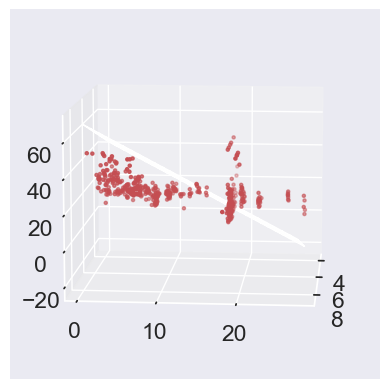

In [19]:
#ANALISIS DE RESULTADOS

#Crear un plano en 3D
x1_range= np.arange(df["RM"].min(), df["RM"].max()) #Tomar los datos desde el menor hasta el mayor
x2_range= np.arange(df["INDUS"].min(), df["INDUS"].max()) #Tomar los datos desde el menor hasta el mayor

X1, X2= np.meshgrid(x1_range, x2_range) #Crear una malla con todos los valores de estas variables

#Crear el plano
plano= pd.DataFrame({"RM": X1.ravel(), "INDUS": X2.ravel()})
pred= slr.predict(plano).reshape(X1.shape)
pred= sc_y.inverse_transform(pred)

#Graficar
fig= plt.figure()
ax= fig.add_subplot(projection='3d')
#ax= fig.gca(projection= "3d")
ax.plot_surface(X1,X2,pred, alpha= 0.4)
ax.scatter3D(df["RM"], df["INDUS"], df["MEDV"], color= "r", marker= ".")
ax.view_init(elev= 10, azim= 5)